# Customer Churn Analysis and Customer Intelligence
**Updated and quality-checked portfolio notebook**  
Tools: SQLite, SQL, pandas, NumPy, Matplotlib, Seaborn.

This notebook addresses the issues found in the previous version:
- Converts support escalation flags (`Y`/`N`) to numeric values before aggregation.
- Aggregates support interactions by customer before joining, avoiding row multiplication.
- Audits missing values and inconsistent categories instead of silently hiding them.
- Treats zero high-risk active customers as a data finding if the supplied data supports it, not automatically as a coding error.
- Uses a clearly documented reporting snapshot date for tenure.


In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Expected folder structure:
# project_root/data/customer_churn.db
# project_root/notebooks/customer_churn_analysis_updated.ipynb
BASE_DIR = Path("..")
DB_PATH = BASE_DIR / "data" / "customer_churn.db"
OUTPUT_DIR = BASE_DIR / "output"
CHART_DIR = OUTPUT_DIR / "charts"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

if not DB_PATH.exists():
    # Allows running this notebook from the project root too.
    alt = Path("data") / "customer_churn.db"
    if alt.exists():
        DB_PATH = alt
    else:
        raise FileNotFoundError(f"Database not found at {DB_PATH.resolve()}. Keep the data folder beside notebooks.")
print("Database:", DB_PATH.resolve())


Database: /mnt/data/Customer_Churn_Analytics_Project/data/customer_churn.db


## 1. Connect to SQLite and inspect the tables

In [2]:
with sqlite3.connect(DB_PATH) as conn:
    table_names = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn
    )["name"].tolist()
    print("Tables:", table_names)
    customers = pd.read_sql_query("SELECT * FROM db_customer", conn)
    subscriptions = pd.read_sql_query("SELECT * FROM db_subscription", conn)
    support = pd.read_sql_query("SELECT * FROM db_support", conn)

print(f"Customers: {customers.shape}")
print(f"Subscriptions: {subscriptions.shape}")
print(f"Support interactions: {support.shape}")
display(customers.head())
display(subscriptions.head())
display(support.head())


Tables: ['db_customer', 'db_subscription', 'db_support']
Customers: (21, 8)
Subscriptions: (21, 11)
Support interactions: (9, 6)


,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,None,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,None,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,None,None,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,None,None,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,None,None,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,None
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,None


## 2. Standardize columns and data types

In [3]:
def standardize_columns(df):
    df = df.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    return df

customers, subscriptions, support = map(standardize_columns, [customers, subscriptions, support])

# Preserve customer IDs as strings (they can contain leading zeros).
for df in [customers, subscriptions, support]:
    df["customerid"] = df["customerid"].astype("string").str.strip()

customers["dob"] = pd.to_datetime(customers["dob"], errors="coerce")
for col in ["subscription_start_date", "renewal_date", "cancellation_date"]:
    subscriptions[col] = pd.to_datetime(subscriptions[col], errors="coerce")
support["complaint_date"] = pd.to_datetime(support["complaint_date"], errors="coerce")

for col in ["monthly_charges", "cltv", "churn_score"]:
    subscriptions[col] = pd.to_numeric(subscriptions[col], errors="coerce")
support["csat_score"] = pd.to_numeric(support["csat_score"], errors="coerce")

# Important fix: escalation is stored as Y/N in the supplied database, not as numbers.
if "escalations" in support.columns:
    escalation_text = support["escalations"].astype("string").str.strip().str.upper()
    escalation_map = {"Y": 1, "YES": 1, "TRUE": 1, "1": 1,
                      "N": 0, "NO": 0, "FALSE": 0, "0": 0}
    mapped = escalation_text.map(escalation_map)
    numeric_fallback = pd.to_numeric(support["escalations"], errors="coerce")
    support["escalation_flag"] = mapped.fillna(numeric_fallback).fillna(0).astype(int)
else:
    support["escalation_flag"] = 0

# Standardize obvious category variants without inventing missing values.
if "gender" in customers.columns:
    customers["gender"] = customers["gender"].astype("string").str.strip().str.title()
    customers["gender"] = customers["gender"].replace({"Women": "Female", "Woman": "Female", "Man": "Male"})
for col in ["country", "state", "interests"]:
    if col in customers.columns:
        customers[col] = customers[col].astype("string").str.strip().replace("", pd.NA)

print("Duplicate customer IDs:", int(customers["customerid"].duplicated().sum()))
print("Duplicate subscription customer IDs:", int(subscriptions["customerid"].duplicated().sum()))
print("\nMissing values by customer column:")
display(customers.isna().sum().to_frame("missing_count"))
print("\nMissing values by subscription column:")
display(subscriptions.isna().sum().to_frame("missing_count"))
print("\nMissing values by support column:")
display(support.isna().sum().to_frame("missing_count"))
print("\nEscalation values after mapping:")
display(support["escalation_flag"].value_counts(dropna=False).rename_axis("escalation_flag").to_frame("interactions"))


Duplicate customer IDs: 0
Duplicate subscription customer IDs: 0

Missing values by customer column:


,missing_count
customerid,0
name,0
country,3
state,0
gender,0
dob,0
interests,17
pincode,21



Missing values by subscription column:


,missing_count
customerid,0
subscription_start_date,0
subscription_type,0
renewal_date,0
plan_type,0
contract_type,0
cancellation_date,15
cancellation_reason,15
monthly_charges,0
cltv,0



Missing values by support column:


,missing_count
customerid,0
complaint_date,0
escalations,0
csat_score,0
col_1,9
comment,5
escalation_flag,0



Escalation values after mapping:


,interactions
escalation_flag,
1,5
0,4


### Data-quality decisions
- `pincode` is entirely missing in this supplied sample, so it is excluded from the analysis dataset (the source database remains unchanged).
- `interests` is mostly missing; retain it only as a descriptive field, not as a basis for conclusions.
- Missing country is labelled `Unknown` in the analysis table.
- The supplied state field contains `Kathmandu`; keep the source value but note that the geographic labels may need business validation.
- Escalation flags are converted from `Y`/`N` to `1`/`0`; this corrects the previous zero-escalation calculation.


In [4]:
# Build support metrics at customer level; preserve all support interactions.
support_summary = support.groupby("customerid", as_index=False).agg(
    complaint_count=("customerid", "size"),
    escalation_count=("escalation_flag", "sum"),
    avg_csat_score=("csat_score", "mean"),
    latest_complaint_date=("complaint_date", "max")
)

# Remove entirely empty pincode from analysis only.
customers_analysis = customers.drop(columns=["pincode"], errors="ignore").copy()
customers_analysis["country"] = customers_analysis["country"].fillna("Unknown")

analysis = customers_analysis.merge(
    subscriptions, on="customerid", how="left", validate="one_to_one"
).merge(
    support_summary, on="customerid", how="left", validate="one_to_one"
)

analysis["complaint_count"] = analysis["complaint_count"].fillna(0).astype(int)
analysis["escalation_count"] = analysis["escalation_count"].fillna(0).astype(int)

assert len(analysis) == len(subscriptions), (
    f"Unexpected row count: {len(analysis)} analysis rows vs {len(subscriptions)} subscriptions"
)
assert analysis["customerid"].is_unique, "Customer IDs are not unique after joining."

print("Joined analysis shape:", analysis.shape)
print("Customers with at least one complaint:", int((analysis["complaint_count"] > 0).sum()))
print("Customers with at least one escalation:", int((analysis["escalation_count"] > 0).sum()))
display(analysis[["customerid", "complaint_count", "escalation_count", "avg_csat_score"]].head(10))


Joined analysis shape: (21, 21)
Customers with at least one complaint: 7
Customers with at least one escalation: 5


,customerid,complaint_count,escalation_count,avg_csat_score
0,0002-ORFBO,0,0,NaN
1,0003-MKNFE,2,1,35.0
2,0004-TLHLJ,0,0,NaN
3,0011-IGKFF,0,0,NaN
4,0013-EXCHZ,1,1,20.0
5,0013-MHZWF,1,0,90.0
6,0013-SMEOE,1,0,30.0
7,0014-BMAQU,0,0,NaN
8,0015-UOCOJ,0,0,NaN
9,0016-QLJIS,0,0,NaN


## 3. Feature engineering

In [5]:
# Historical snapshot: chosen to align with the report's 2024 analysis period.
# Change this date only when intentionally analyzing a different reporting period.
AS_OF_DATE = pd.Timestamp("2024-09-30")

analysis["is_churned"] = analysis["cancellation_date"].notna()
analysis["end_date_for_tenure"] = analysis["cancellation_date"].fillna(AS_OF_DATE)
analysis["tenure_days"] = (
    analysis["end_date_for_tenure"] - analysis["subscription_start_date"]
).dt.days

# Flag data rows that are not sensible for the chosen snapshot; don't silently alter them.
analysis["tenure_date_issue"] = analysis["tenure_days"] < 0
analysis["churn_month"] = analysis["cancellation_date"].dt.to_period("M").astype("string")

analysis["risk_tier"] = pd.cut(
    analysis["churn_score"],
    bins=[-np.inf, 39, 69, np.inf],
    labels=["Low", "Medium", "High"],
    right=True
)
# Revenue at risk is defined only for active customers with score > 70.
analysis["revenue_at_risk"] = np.where(
    (~analysis["is_churned"]) & (analysis["churn_score"] > 70),
    analysis["monthly_charges"].fillna(0),
    0.0
)

print("Negative tenure/date issues:", int(analysis["tenure_date_issue"].sum()))
display(analysis[["customerid", "is_churned", "tenure_days", "tenure_date_issue",
                  "churn_score", "risk_tier", "revenue_at_risk"]])


Negative tenure/date issues: 0


,customerid,is_churned,tenure_days,tenure_date_issue,churn_score,risk_tier,revenue_at_risk
0,0002-ORFBO,False,1295,False,12,Low,0.0
1,0003-MKNFE,True,1501,False,91,High,0.0
2,0004-TLHLJ,False,680,False,34,Low,0.0
3,0011-IGKFF,False,1970,False,8,Low,0.0
4,0013-EXCHZ,True,419,False,88,High,0.0
5,0013-MHZWF,False,835,False,22,Low,0.0
6,0013-SMEOE,True,1142,False,79,High,0.0
7,0014-BMAQU,False,1690,False,5,Low,0.0
8,0015-UOCOJ,False,436,False,34,Low,0.0
9,0016-QLJIS,False,911,False,41,Medium,0.0


## 4. KPI calculations

In [6]:
total_customers = int(analysis["customerid"].nunique())
churned_customers = int(analysis["is_churned"].sum())
churn_rate = churned_customers / total_customers if total_customers else 0.0
retention_rate = 1.0 - churn_rate

monthly_mask = analysis["contract_type"].astype("string").str.lower().str.contains("month", na=False)
annual_mask = analysis["contract_type"].astype("string").str.lower().str.contains("annual|year", regex=True, na=False)

def segment_churn_rate(mask):
    subset = analysis.loc[mask]
    return float(subset["is_churned"].mean()) if len(subset) else np.nan

kpis = pd.DataFrame([
    ("Total customers", total_customers),
    ("Churned customers", churned_customers),
    ("Churn rate (%)", round(churn_rate * 100, 2)),
    ("Retention rate (%)", round(retention_rate * 100, 2)),
    ("Average tenure (days; valid dates)", round(analysis.loc[~analysis["tenure_date_issue"], "tenure_days"].dropna().mean(), 2)),
    ("Monthly contract churn rate (%)", round(segment_churn_rate(monthly_mask) * 100, 2)),
    ("Annual contract churn rate (%)", round(segment_churn_rate(annual_mask) * 100, 2)),
    ("Customers with complaints", int((analysis["complaint_count"] > 0).sum())),
    ("Total support interactions", int(support["customerid"].notna().sum())),
    ("Customers with escalations", int((analysis["escalation_count"] > 0).sum())),
    ("Total escalated interactions", int(analysis["escalation_count"].sum())),
    ("Active high-risk customers (score > 70)", int(((analysis["churn_score"] > 70) & (~analysis["is_churned"])).sum())),
    ("Active high-risk monthly charges", round(float(analysis["revenue_at_risk"].sum()), 2)),
], columns=["metric", "value"])
display(kpis)
kpis.to_csv(OUTPUT_DIR / "kpi_summary.csv", index=False)
kpis.to_json(OUTPUT_DIR / "kpi_summary.json", orient="records", indent=2)


,metric,value
0,Total customers,21.00
1,Churned customers,6.00
2,Churn rate (%),28.57
3,Retention rate (%),71.43
4,Average tenure (days; valid dates),1028.71
5,Monthly contract churn rate (%),55.56
6,Annual contract churn rate (%),8.33
7,Customers with complaints,7.00
8,Total support interactions,9.00
9,Customers with escalations,5.00


## 5. Exploratory data analysis

In [7]:
def churn_segment(column):
    return (analysis.groupby(column, dropna=False).agg(
        customers=("customerid", "nunique"),
        churned_customers=("is_churned", "sum"),
        churn_rate=("is_churned", "mean"),
        avg_monthly_charges=("monthly_charges", "mean")
    ).assign(churn_rate_pct=lambda d: (d["churn_rate"] * 100).round(2))
     .sort_values("churn_rate", ascending=False))

for col in ["contract_type", "plan_type", "state", "cancellation_reason"]:
    print(f"Churn analysis by {col}")
    subset = analysis if col != "cancellation_reason" else analysis.loc[analysis["is_churned"]]
    if col in subset.columns:
        display(subset.groupby(col, dropna=False).agg(
            customers=("customerid", "nunique"),
            churn_rate=("is_churned", "mean")
        ).assign(churn_rate_pct=lambda d: (d["churn_rate"] * 100).round(2))
          .sort_values("churn_rate", ascending=False))


Churn analysis by contract_type


,customers,churn_rate,churn_rate_pct
contract_type,,,
Monthly,9,0.555556,55.56
Annual,12,0.083333,8.33


Churn analysis by plan_type


,customers,churn_rate,churn_rate_pct
plan_type,,,
Basic,5,0.600000,60.00
Standard,9,0.222222,22.22
Premium,7,0.142857,14.29


Churn analysis by state


,customers,churn_rate,churn_rate_pct
state,,,
Karnataka,2,1.000000,100.00
Meghalaya,3,0.666667,66.67
Telangana,2,0.500000,50.00
Delhi,4,0.250000,25.00
Kathmandu,2,0.000000,0.00
Maharashtra,3,0.000000,0.00
Nagaland,1,0.000000,0.00
Rajasthan,2,0.000000,0.00
Uttar Pradesh,2,0.000000,0.00


Churn analysis by cancellation_reason


,customers,churn_rate,churn_rate_pct
cancellation_reason,,,
Forgot to cancel trial,1,1.0,100.0
Not enough content,1,1.0,100.0
Poor streaming quality,1,1.0,100.0
Switched to competitor,2,1.0,100.0
Too expensive,1,1.0,100.0


## 6. Visualizations

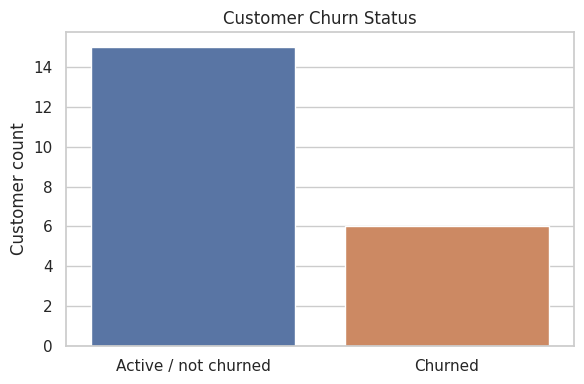

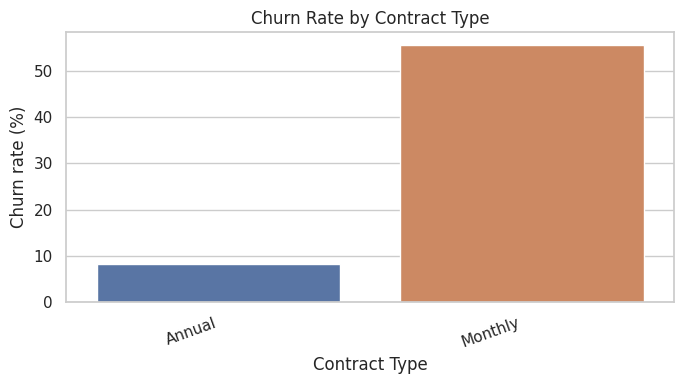

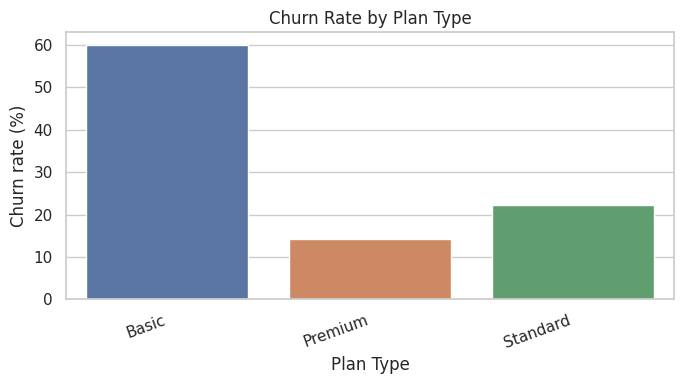

,is_churned,customers,avg_escalations,avg_csat,churn_status
0,False,15,0.000000,90.000000,Active
1,True,6,0.833333,31.666667,Churned


In [8]:
# Churn status
plt.figure(figsize=(6, 4))
status = analysis["is_churned"].map({False: "Active / not churned", True: "Churned"}).value_counts()
sns.barplot(x=status.index, y=status.values, hue=status.index, legend=False)
plt.title("Customer Churn Status")
plt.xlabel("")
plt.ylabel("Customer count")
plt.tight_layout()
plt.savefig(CHART_DIR / "churn_status.png", dpi=160, bbox_inches="tight")
plt.show()

# Churn rate by contract and plan
for column, filename in [("contract_type", "churn_by_contract.png"), ("plan_type", "churn_by_plan.png")]:
    rates = (analysis.groupby(column, dropna=False)["is_churned"].mean()
             .mul(100).reset_index(name="churn_rate_pct"))
    plt.figure(figsize=(7, 4))
    sns.barplot(data=rates, x=column, y="churn_rate_pct", hue=column, legend=False)
    plt.title(f"Churn Rate by {column.replace('_', ' ').title()}")
    plt.ylabel("Churn rate (%)")
    plt.xlabel(column.replace("_", " ").title())
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.savefig(CHART_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

# Support escalations by churn status
support_by_churn = analysis.groupby("is_churned").agg(
    customers=("customerid", "nunique"),
    avg_escalations=("escalation_count", "mean"),
    avg_csat=("avg_csat_score", "mean")
).reset_index()
support_by_churn["churn_status"] = support_by_churn["is_churned"].map({False: "Active", True: "Churned"})
display(support_by_churn)


## 7. Export cleaned data and data-quality report

In [9]:
# Save the complete customer-level analysis and a compact quality report.
analysis.to_csv(OUTPUT_DIR / "cleaned_customer_churn.csv", index=False)
quality_report = pd.DataFrame({
    "column": analysis.columns,
    "missing_count": [int(analysis[c].isna().sum()) for c in analysis.columns],
    "missing_pct": [round(float(analysis[c].isna().mean() * 100), 2) for c in analysis.columns]
})
quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=False)

findings = {
    "reporting_snapshot_date": AS_OF_DATE.strftime("%Y-%m-%d"),
    "total_customers": total_customers,
    "churned_customers": churned_customers,
    "churn_rate_pct": round(churn_rate * 100, 2),
    "retention_rate_pct": round(retention_rate * 100, 2),
    "customers_with_complaints": int((analysis["complaint_count"] > 0).sum()),
    "customers_with_escalations": int((analysis["escalation_count"] > 0).sum()),
    "total_escalated_interactions": int(analysis["escalation_count"].sum()),
    "active_high_risk_customers": int(((analysis["churn_score"] > 70) & (~analysis["is_churned"])).sum()),
    "notes": [
        "Escalations Y/N were mapped to 1/0.",
        "Support interactions were aggregated by customer before joining.",
        "Zero active high-risk customers is the result for this sample if shown above; it is not assumed to be an error.",
        "The dataset is small and findings should be treated as directional."
    ]
}
with open(OUTPUT_DIR / "analysis_findings.json", "w", encoding="utf-8") as f:
    import json
    json.dump(findings, f, indent=2)

print("Files saved:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print("-", p)


Files saved:
- ../output/analysis_findings.json
- ../output/charts/churn_by_contract.png
- ../output/charts/churn_by_plan.png
- ../output/charts/churn_status.png
- ../output/charts/risk_vs_charges.png
- ../output/cleaned_customer_churn.csv
- ../output/data_quality_report.csv
- ../output/kpi_summary.csv
- ../output/kpi_summary.json


## 8. Business interpretation and recommendations
1. Monthly contracts have a higher observed churn rate than annual contracts in this sample; investigate whether contract flexibility, pricing, or content satisfaction contributes.
2. Escalations are now correctly derived from the source `Y`/`N` flags. Review the escalation count and compare complaint/CSAT patterns by churn status.
3. If no active customers have a churn score above 70, do not invent an at-risk revenue figure. Instead, review the score distribution and consider a lower threshold only if the business defines one.
4. Review cancellation reasons and the states with high observed churn, but validate geographic values and sample size before drawing conclusions.
5. The sample contains only 21 subscriptions and 9 support interactions; results are illustrative, not statistically conclusive.

**Important date note:** this notebook uses 2024-09-30 as a historical snapshot for active-customer tenure. Some cancellation dates may fall after this date, so `tenure_date_issue` flags rows with negative tenure relative to that snapshot. Review these flagged rows or choose a snapshot date consistent with the business reporting period before publishing average tenure.
